# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [23]:
# Propósito: instalar ddgs, la librería que busca imágenes en internet (DuckDuckGo y otros motores).
# Se necesita antes de importar DDGS en la siguiente celda; en Colab no viene instalada.
# -q = salida silenciosa; -U = actualiza a la última versión si ya estaba instalada.
!pip -q install -U ddgs


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
# Propósito: importar todas las librerías del taller y fijar la semilla aleatoria.
# Fijar la semilla hace que los resultados sean reproducibles (iguales al repetir la ejecución).

import os
# Keras 3 puede usar varios "motores" de cálculo (backends); se elige TensorFlow antes de importar keras.
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path  # manejo de rutas de carpetas y archivos
import hashlib, io, random, shutil, time  # hashes, bytes en memoria, azar, copiar archivos, pausas
import numpy as np  # cálculos con arreglos numéricos
import matplotlib.pyplot as plt  # gráficas e imágenes
import requests  # descargar archivos desde una URL
from PIL import Image  # abrir, convertir y guardar imágenes

import tensorflow as tf
import keras
from keras import layers  # capas para construir el modelo (Dense, Dropout, etc.)
from ddgs import DDGS  # buscador de imágenes
# Métricas de evaluación: reporte por clase (precision/recall/F1) y matriz de confusión.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42  # semilla: cualquier número fijo sirve; 42 es una convención
random.seed(SEED)  # azar de Python (mezclas, muestras aleatorias)
np.random.seed(SEED)  # azar de NumPy
tf.random.set_seed(SEED)  # azar de TensorFlow (pesos iniciales, data augmentation)

# Versiones y GPU disponibles: sirven para reportar el entorno. Si GPU sale [], se entrena en CPU (más lento).
print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.15.1
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [25]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
# Propósito: definir las 3 clases del problema y los términos con que se buscarán sus imágenes.
# Cada clave del diccionario será el nombre de una carpeta y, por lo tanto, el nombre de una clase.
# Las búsquedas van en inglés porque el buscador devuelve más y mejores fotos en ese idioma.
# Cada búsqueda devuelve como máximo ~35 imágenes, por eso se usan 5–6 búsquedas por clase para acercarse a 100.
# Espresso lleva una búsqueda más porque en la primera ejecución muchas de sus descargas fallaron.
SEARCHES = {
    "espresso": [
        "espresso shot in small cup",  # taza pequeña con poco líquido y crema
        "espresso coffee demitasse crema",  # "demitasse" = taza pequeña típica del espresso
        "espresso coffee cup",
        "single espresso shot white cup",
        "espresso cup on saucer",  # taza sobre plato, encuadre típico de cafetería
        "espresso crema close up",  # primer plano de la crema marrón
    ],
    "cappuccino": [
        "cappuccino cup foam top view",  # vista superior: muestra la espuma blanca y espesa
        "cappuccino coffee milk foam",
        "cappuccino with cocoa powder",  # cacao espolvoreado sobre la espuma
        "cappuccino cup on saucer",
        "cappuccino coffee cup",
    ],
    "latte": [
        "caffe latte tall glass",  # el latte suele servirse en vaso alto, color más claro
        "latte coffee cup",
        "latte coffee glass",
        "cafe latte mug",  # taza grande
        "caffe latte coffee drink",
    ],
}

SEARCHES  # muestra el diccionario para verificar clases y búsquedas

{'espresso': ['espresso shot in small cup',
  'espresso coffee demitasse crema',
  'espresso coffee cup',
  'single espresso shot white cup',
  'espresso cup on saucer',
  'espresso crema close up'],
 'cappuccino': ['cappuccino cup foam top view',
  'cappuccino coffee milk foam',
  'cappuccino with cocoa powder',
  'cappuccino cup on saucer',
  'cappuccino coffee cup'],
 'latte': ['caffe latte tall glass',
  'latte coffee cup',
  'latte coffee glass',
  'cafe latte mug',
  'caffe latte coffee drink']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Respuesta:**

- **Características visuales esperadas:** el espresso es poco líquido en taza pequeña, muy oscuro y con una capa fina de crema marrón; el cappuccino tiene una capa gruesa de espuma de leche blanca, a veces con cacao encima; el latte es más claro, con poca espuma, y suele servirse en vaso alto o taza grande.
- **Imágenes incorrectas esperadas:** granos de café, máquinas de espresso, logos y empaques de cafeterías, dibujos, tazas vacías y bebidas frías (*iced latte*).
- **Sesgo o *data leakage*** (información que se filtra entre conjuntos y hace que el modelo parezca mejor de lo que es): el *latte art* (dibujo con la leche) aparece en cappuccinos y lattes, así que el modelo podría guiarse por el tamaño del vaso o el fondo de la cafetería en vez de la bebida; además, la misma foto de un banco de imágenes puede salir en varias búsquedas y quedar a la vez en train y test.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [26]:
# Propósito: definir las funciones que buscan imágenes por clase, las descargan, las filtran y las guardan.
# Es el primer paso para construir un dataset propio: una carpeta por clase con archivos .jpg.

RAW_DIR = Path("data_raw")  # carpeta donde quedan las imágenes "crudas" (sin dividir en train/val/test)
RAW_DIR.mkdir(exist_ok=True)  # la crea; exist_ok=True evita error si ya existe

# Calcula el hash SHA-256 de un archivo: una "huella digital" de 64 caracteres.
# Dos archivos con exactamente los mismos bytes tienen el mismo hash; así se detectan duplicados exactos.
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:  # "rb" = leer en modo binario (bytes)
        # Lee el archivo en bloques de 1 MB (1024*1024 bytes) hasta que read devuelve b"" (fin del archivo).
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)  # agrega cada bloque al cálculo del hash
    return h.hexdigest()  # hash final como texto hexadecimal

# images_per_query=60: máximo de resultados por búsqueda; min_side=120: descarta imágenes con lado menor a 120 px;
# timeout=8: espera máximo 8 segundos por descarga para no bloquearse con servidores lentos.
def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()  # reutiliza la conexión entre descargas (más rápido)
    # Algunos servidores rechazan peticiones que no parecen venir de un navegador; este encabezado lo simula.
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    # Ojo: estos hashes son de los .jpg ya re-guardados, no de los bytes originales descargados (ver más abajo).
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")  # todos los .jpg dentro de las subcarpetas de clase
        if path.is_file()
    }

    for class_name, queries in searches.items():  # recorre cada clase y su lista de búsquedas
        class_dir = root / class_name  # carpeta de la clase, por ejemplo data_raw/espresso
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))  # cuenta lo ya guardado para continuar la numeración
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")  # !r muestra el texto entre comillas
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",  # filtra contenido explícito
                    max_results=images_per_query,
                    license_image="any",  # "any" = cualquier licencia Creative Commons (si el motor lo soporta)
                )
            except Exception as e:
                # Si la búsqueda falla (límite de peticiones, sin internet), se informa y se pasa a la siguiente.
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")  # cada resultado es un diccionario; "image" es la URL de la imagen
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)  # descarga la imagen
                    response.raise_for_status()  # lanza error si el servidor respondió con fallo (404, 403...)
                    data = response.content  # bytes de la imagen descargada
                    digest = hashlib.sha256(data).hexdigest()  # hash de los bytes originales
                    if digest in seen_hashes:  # duplicado exacto: se omite
                        continue

                    # io.BytesIO permite abrir los bytes como si fueran un archivo, sin guardarlos antes.
                    with Image.open(io.BytesIO(data)) as img:
                        # RGB = 3 canales de color; quita transparencia o escala de grises que el modelo no espera.
                        img = img.convert("RGB")
                        if min(img.size) < min_side:  # img.size = (ancho, alto); descarta imágenes muy pequeñas
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"  # nombre con 4 dígitos: 0000.jpg, 0001.jpg...
                        img.save(filename, format="JPEG", quality=90)  # quality=90: buena calidad, archivo liviano

                    seen_hashes.add(digest)  # registra el hash para no guardar la misma imagen otra vez
                    saved += 1
                except Exception:
                    # Cualquier fallo (URL caída, archivo que no es imagen) se ignora y se sigue con la siguiente.
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)  # pausa de 1 s entre búsquedas para no ser bloqueado por el buscador

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [27]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
# Propósito: ejecutar la descarga real usando las clases y búsquedas definidas en SEARCHES.
# Con 2 búsquedas de hasta 60 resultados, cada clase puede llegar a ~120 imágenes (menos, por fallos y filtros).
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== espresso ===
Buscando: 'espresso shot in small cup'
  Total guardadas hasta ahora: 35
Buscando: 'espresso coffee demitasse crema'
  Total guardadas hasta ahora: 64
Buscando: 'espresso coffee cup'
  Total guardadas hasta ahora: 96
Buscando: 'single espresso shot white cup'
  Total guardadas hasta ahora: 124
Buscando: 'espresso cup on saucer'
  Total guardadas hasta ahora: 153
Buscando: 'espresso crema close up'
  Total guardadas hasta ahora: 184

=== cappuccino ===
Buscando: 'cappuccino cup foam top view'
  Total guardadas hasta ahora: 35
Buscando: 'cappuccino coffee milk foam'
  Total guardadas hasta ahora: 70
Buscando: 'cappuccino with cocoa powder'
  Total guardadas hasta ahora: 104
Buscando: 'cappuccino cup on saucer'
  Total guardadas hasta ahora: 135
Buscando: 'cappuccino coffee cup'


c:\Users\Emmanuel\Documents\ENTREGABLES IA\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 167

=== latte ===
Buscando: 'caffe latte tall glass'
  Total guardadas hasta ahora: 35
Buscando: 'latte coffee cup'
  Total guardadas hasta ahora: 68
Buscando: 'latte coffee glass'
  Total guardadas hasta ahora: 103
Buscando: 'cafe latte mug'
  Total guardadas hasta ahora: 135
Buscando: 'caffe latte coffee drink'
  Error en búsqueda: RequestError: RequestError('error sending request for url (https://duckduckgo.com/?q=caffe+latte+coffee+drink) > user error: malformed headers')

Descarga terminada.


In [28]:
# Propósito: contar cuántas imágenes hay en cada carpeta de clase.
# Sirve para revisar si las clases están balanceadas (cantidades parecidas) antes de entrenar.
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):  # sorted da un orden alfabético estable
        if folder.is_dir():  # solo cuenta carpetas (cada una es una clase)
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

# Resultado: diccionario {clase: número de imágenes}; la meta es ~100–150 imágenes útiles por clase.
count_images(RAW_DIR)

{'cappuccino': 167, 'espresso': 184, 'latte': 135}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [29]:
# Propósito: borrar las imágenes que TensorFlow no puede leer (validación técnica).
# Si quedara alguna, model.fit() fallaría en medio del entrenamiento.
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []  # lista de archivos que fallaron

    for path in root_dir.rglob("*.jpg"):  # rglob busca en todas las subcarpetas (recursivo)
        try:
            raw = tf.io.read_file(str(path))  # lee los bytes del archivo

            # Decodifica con el mismo lector que usará Keras al entrenar.
            img = tf.io.decode_image(
                raw,
                channels=3,  # exige 3 canales (RGB)
                expand_animations=False,  # si es un GIF animado, toma solo el primer cuadro (imagen 2D)
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])  # solo la primera línea del error, para no llenar la pantalla
            bad_files.append(path)

    # Se borran al final, para no modificar la carpeta mientras se recorre.
    for path in bad_files:
        path.unlink(missing_ok=True)  # unlink = borrar archivo; missing_ok evita error si ya no existe

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [30]:
# Propósito: repetir la validación técnica y detener el notebook si todavía hay imágenes ilegibles.
# Garantiza que el pipeline de Keras no fallará por archivos dañados.
bad_files = remove_invalid_images(RAW_DIR)

# assert detiene la ejecución con este mensaje si la condición es falsa (si quedan imágenes inválidas).
assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

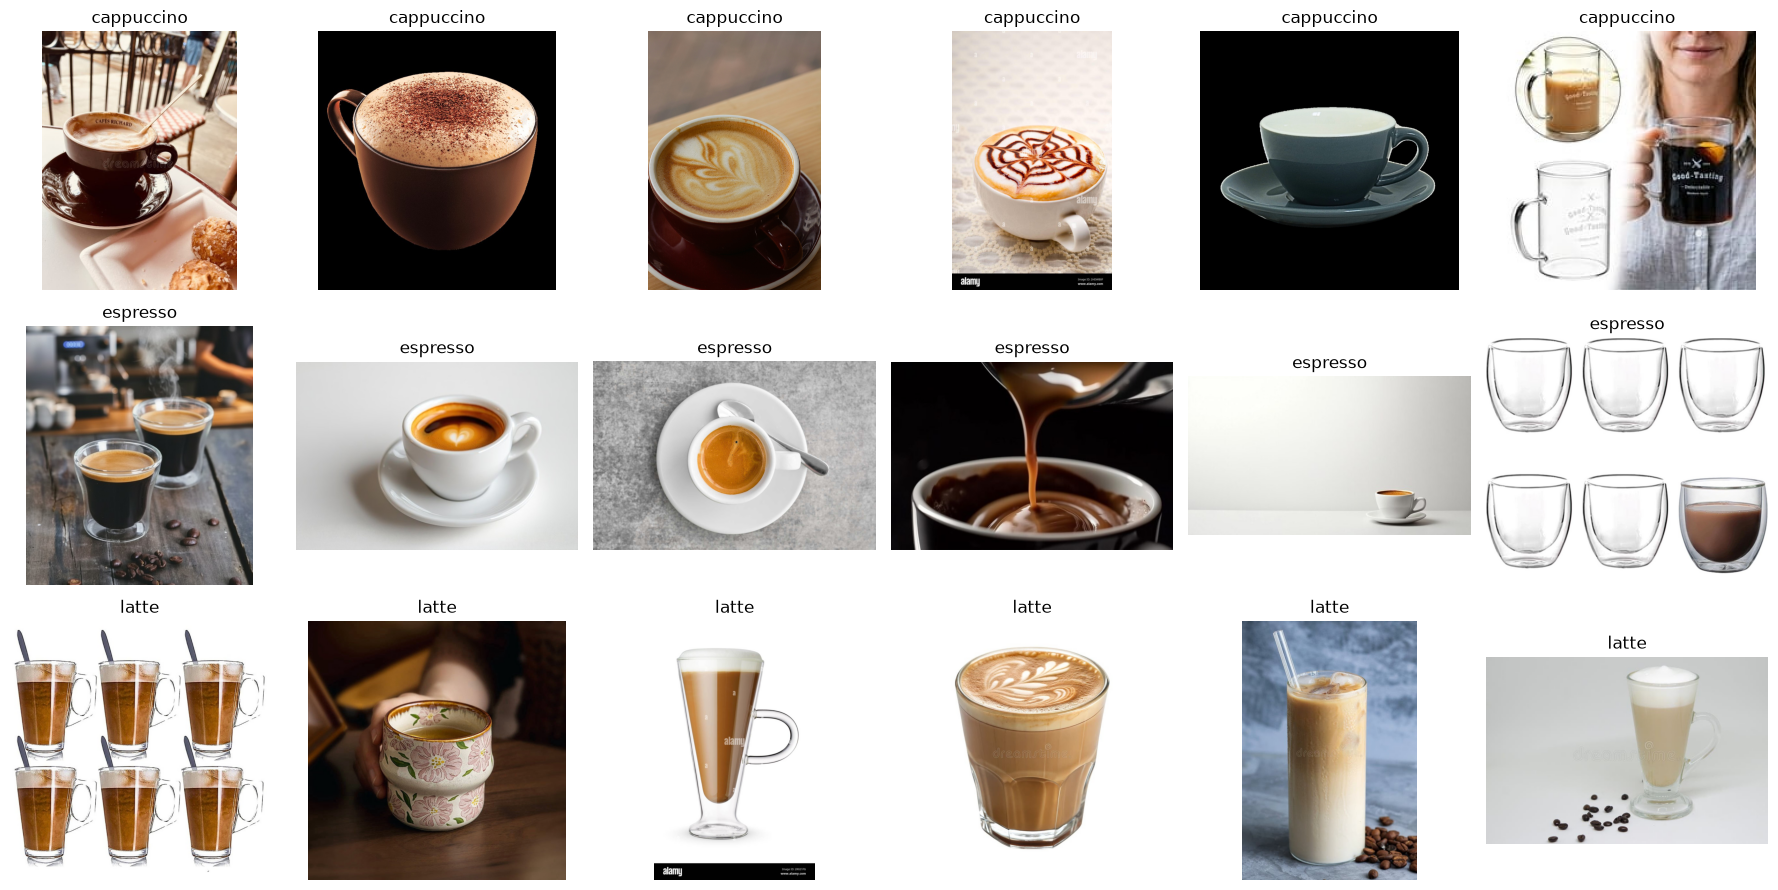

In [31]:
# Propósito: mostrar imágenes al azar de cada clase para revisarlas a ojo (validación semántica).
# Permite detectar fotos de la clase equivocada, logos, dibujos o fondos repetidos.
def show_random_images(root, n_per_class=6):  # n_per_class=6: 6 imágenes por fila
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]  # una carpeta por clase
    # Cuadrícula: una fila por clase y n_per_class columnas; cada imagen ocupa ~3x3 pulgadas.
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        # Con una sola fila, axes es 1D; se le agrega una dimensión para poder usar axes[fila, columna].
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        # random.sample elige sin repetir; min(...) evita error si la clase tiene menos de 6 imágenes.
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)  # título = clase (carpeta) de la que viene la imagen
            ax.axis("off")  # oculta los ejes numéricos
    plt.tight_layout()  # ajusta márgenes para que no se superpongan los títulos

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

**Registro del dataset:**

- **Imágenes por clase:** cappuccino 167, espresso 184 y latte 135 (salida de `count_images`). La clase más pequeña (latte) tiene ~20 % menos imágenes que la más grande; es un desbalance moderado.
- **Imágenes eliminadas:** 0 inválidas (validación técnica) y 0 eliminadas a mano: no se hizo limpieza manual, por eso los totales de la división coinciden con la descarga.
- **Problema de calidad más frecuente:** fotos de producto sin bebida (tazas o vasos vacíos, juegos de tazas, collages). Aparecen en la muestra de `show_random_images` y en varios errores del modelo. También hay marcas de agua (alamy, dreamstime) y algunas bebidas frías.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [32]:
# Propósito: dividir las imágenes de cada clase en train (70 %), validation (15 %) y test (15 %).
# Se separa antes de entrenar para evaluar con imágenes que el modelo nunca vio.
SPLIT_DIR = Path("dataset")  # carpeta destino con la estructura dataset/<split>/<clase>/

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)  # borra una división anterior para no mezclar archivos viejos
    rng = random.Random(seed)  # generador de azar propio con semilla: la división es reproducible

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)  # mezcla para que cada conjunto tenga imágenes de todas las búsquedas
        n = len(files)
        n_train = int(n * train_ratio)  # int() redondea hacia abajo; por ejemplo 120 * 0.70 = 84
        n_val = int(n * val_ratio)  # 120 * 0.15 = 18
        splits = {
            "train": files[:n_train],  # primeras n_train imágenes
            "validation": files[n_train:n_train+n_val],  # las siguientes n_val
            "test": files[n_train+n_val:],  # el resto (por el redondeo puede ser un poco más del 15 %)
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name  # ej.: dataset/train/espresso
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)  # copia (no mueve): data_raw queda intacta

split_dataset(RAW_DIR, SPLIT_DIR)
# Muestra cuántas imágenes por clase quedaron en cada conjunto; deben respetar aprox. 70/15/15.
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'cappuccino': 116, 'espresso': 128, 'latte': 94}
validation {'cappuccino': 25, 'espresso': 27, 'latte': 20}
test {'cappuccino': 26, 'espresso': 29, 'latte': 21}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:**
Cada vez que escogemos épocas, `learning_rate` o capas porque dan mejor resultado en test, ajustamos el modelo a esas imágenes concretas: test deja de ser un conjunto "nunca visto".
La accuracy final queda optimista, es decir, más alta de lo que se obtendría con imágenes nuevas; es como estudiar con las preguntas exactas del examen.
Por eso las decisiones se toman con validation, y test se usa una sola vez, al final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [33]:
# Propósito: convertir las carpetas de imágenes en datasets de Keras listos para entrenar.
# Cada dataset entrega lotes (batches) de imágenes 224x224 con su etiqueta numérica.
IMG_SIZE = (224, 224)  # tamaño de entrada con el que EfficientNetB0 fue entrenada en ImageNet
BATCH_SIZE = 32  # el modelo procesa 32 imágenes a la vez antes de actualizar los pesos

# image_dataset_from_directory usa el nombre de cada subcarpeta como clase (orden alfabético).
# label_mode="int": etiqueta como entero (0, 1, 2), compatible con SparseCategoricalCrossentropy.
# shuffle=True solo en train: mezclar evita que el modelo vea todas las imágenes de una clase seguidas.
train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
# shuffle=False en validation y test: orden estable para que predicciones y etiquetas coincidan al evaluar.
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names  # nombres en orden alfabético: el índice 0 es la primera clase
NUM_CLASSES = len(class_names)  # 3 en este problema; define las neuronas de la capa de salida
AUTOTUNE = tf.data.AUTOTUNE  # deja que TensorFlow elija automáticamente cuántos lotes preparar
# prefetch prepara el siguiente lote mientras el modelo entrena con el actual: reduce tiempos muertos.
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)  # con estas clases debería mostrar ['cappuccino', 'espresso', 'latte']

Found 338 files belonging to 3 classes.
Found 72 files belonging to 3 classes.
Found 76 files belonging to 3 classes.
['cappuccino', 'espresso', 'latte']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [34]:
# Propósito: construir el modelo de transfer learning: EfficientNetB0 congelada + una cabeza nueva de 3 clases.
# Se reutiliza lo que la red ya aprendió en ImageNet porque tenemos pocas imágenes propias.

# Data augmentation: variaciones aleatorias de cada imagen, solo durante el entrenamiento (en predicción no actúan).
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),  # voltea la imagen de izquierda a derecha la mitad de las veces
    layers.RandomRotation(0.08),  # gira hasta ±0.08 de vuelta completa (0.08 × 360° ≈ ±29°)
    layers.RandomZoom(0.10),  # acerca o aleja hasta un 10 %
], name="augmentation")

# include_top=False: quita la capa final original de 1000 clases de ImageNet; queda el extractor de características.
# weights="imagenet": carga los pesos ya entrenados. input_shape=(224, 224, 3): alto, ancho y 3 canales RGB.
base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False  # congela la base: sus ≈4 millones de pesos no cambian al entrenar

inputs = keras.Input(shape=(*IMG_SIZE, 3))  # pixeles 0–255; EfficientNet de Keras ya incluye su propia normalización
x = data_augmentation(inputs)
# training=False: la base funciona en modo inferencia (BatchNormalization usa sus estadísticas guardadas),
# incluso si después se descongela para fine-tuning.
x = base_model(x, training=False)  # salida: mapas de 7x7 con 1280 canales (características visuales)
x = layers.GlobalAveragePooling2D()(x)  # promedio de cada canal: 7x7x1280 → vector de 1280 valores
x = layers.Dropout(0.2)(x)  # apaga al azar el 20 % de los valores al entrenar para reducir el sobreajuste
# Capa de salida: una neurona por clase. Softmax convierte los valores en probabilidades que suman 1:
# p_i = e^(z_i) / suma(e^(z_j)). Parámetros entrenables: 1280 × 3 pesos + 3 sesgos = 3 843.
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)  # une entrada y salida en un solo modelo
# Resumen: capas, forma de salida y número de parámetros. "Trainable params" debe ser 3 843 (solo la cabeza).
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción (antes de entrenar):**

- **¿`train_accuracy` sube rápido?** Sí, en las primeras épocas: la base congelada ya extrae características útiles aprendidas en ImageNet y solo se entrenan los 3 843 parámetros de la cabeza. Como espresso, cappuccino y latte se parecen, es probable que no llegue a valores tan altos como con clases muy distintas.
- **Señal de *overfitting*** (sobreajuste: el modelo memoriza train y no generaliza): `accuracy` sigue subiendo mientras `val_accuracy` se estanca o baja, o `val_loss` empieza a subir mientras `loss` sigue bajando.

In [35]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento
# Propósito: configurar cómo aprende el modelo (optimizador, pérdida, métrica) y entrenar solo la cabeza.
# Se usa validation para vigilar el sobreajuste y detener el entrenamiento a tiempo.

model.compile(
    # Adam: optimizador que ajusta el tamaño del paso de cada peso automáticamente.
    # learning_rate=1e-3 (0.001): tamaño de paso normal, adecuado porque la cabeza empieza desde cero.
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    # Pérdida = -log(probabilidad que el modelo dio a la clase real), promediada en el lote.
    # "Sparse" porque las etiquetas son enteros (0, 1, 2) y no vectores one-hot.
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],  # accuracy = predicciones correctas / total de imágenes
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # vigila la pérdida en validación, no en train
    patience=2,  # tolera 2 épocas seguidas sin mejora antes de detenerse
    restore_best_weights=True,  # al terminar, vuelve a los pesos de la época con menor val_loss
)

history = model.fit(
    train_ds,  # datos con los que se actualizan los pesos
    validation_data=val_ds,  # datos para medir val_loss y val_accuracy al final de cada época
    epochs=10,  # máximo de pasadas completas por train; EarlyStopping puede cortar antes
    callbacks=[early_stopping],
)
# history.history guarda, por época, loss, accuracy, val_loss y val_accuracy (se grafican en la siguiente celda).

Epoch 1/10


c:\Users\Emmanuel\Documents\ENTREGABLES IA\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


11/11 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.3876 - loss: 1.1214 - val_accuracy: 0.5972 - val_loss: 0.9152
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 748ms/step - accuracy: 0.5947 - loss: 0.8935 - val_accuracy: 0.7778 - val_loss: 0.7518
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 764ms/step - accuracy: 0.7278 - loss: 0.7320 - val_accuracy: 0.7778 - val_loss: 0.6552
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 771ms/step - accuracy: 0.8047 - loss: 0.6459 - val_accuracy: 0.7917 - val_loss: 0.5954
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 817ms/step - accuracy: 0.8018 - loss: 0.6051 - val_accuracy: 0.8194 - val_loss: 0.5624
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 383s 38s/step - accuracy: 0.8254 - loss: 0.5447 - val_accuracy: 0.8611 - val_loss: 0.5270
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8373 - loss: 0.5199 - val_accuracy: 0.8611 - val_loss: 0.5105
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 850ms/step - accuracy: 0.8521 - loss: 0.4983 - val_accuracy: 0.8333 - val_los

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

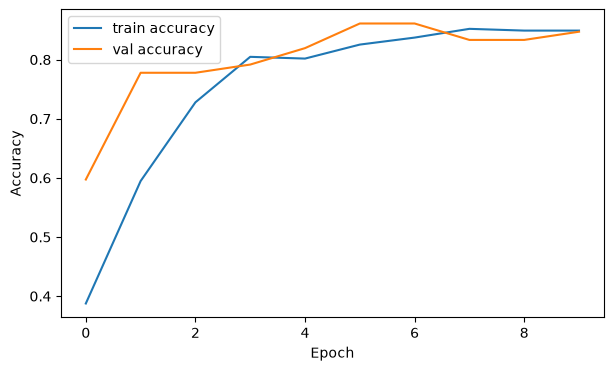

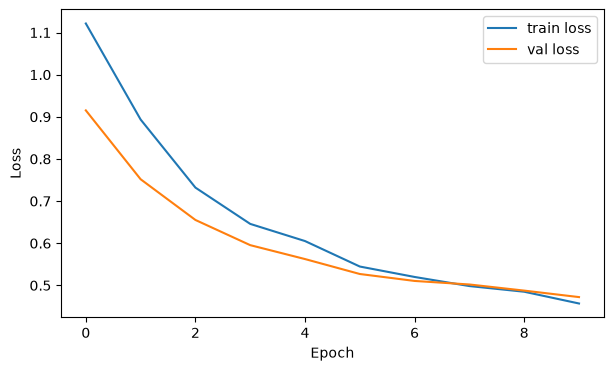

In [36]:
# Completa las cuatro curvas usando el objeto history
# Propósito: graficar las curvas de aprendizaje para ver si el modelo aprende y si hay sobreajuste.
# Lectura: si train sube y validation se queda atrás o baja, hay sobreajuste; si ambas suben juntas, va bien.
plt.figure(figsize=(7, 4))  # tamaño de la figura en pulgadas (ancho, alto)
plt.plot(history.history["accuracy"], label="train accuracy")  # accuracy en train por época
plt.plot(history.history["val_accuracy"], label="val accuracy")  # accuracy en validation por época
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")  # pérdida en train: debería bajar
plt.plot(history.history["val_loss"], label="val loss")  # si sube mientras train loss baja → sobreajuste
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [37]:
# Propósito: medir el desempeño del primer modelo (base congelada) en test, por primera vez.
# Este valor es la línea base para comparar después del fine-tuning.
# evaluate devuelve [pérdida, accuracy] en el orden definido en compile; verbose=0 oculta la barra de progreso.
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
# :.4f = 4 decimales; por ejemplo 0.8500 significa 85 % de imágenes de test bien clasificadas.
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.7632


              precision    recall  f1-score   support

  cappuccino      0.731     0.731     0.731        26
    espresso      0.793     0.793     0.793        29
       latte      0.762     0.762     0.762        21

    accuracy                          0.763        76
   macro avg      0.762     0.762     0.762        76
weighted avg      0.763     0.763     0.763        76



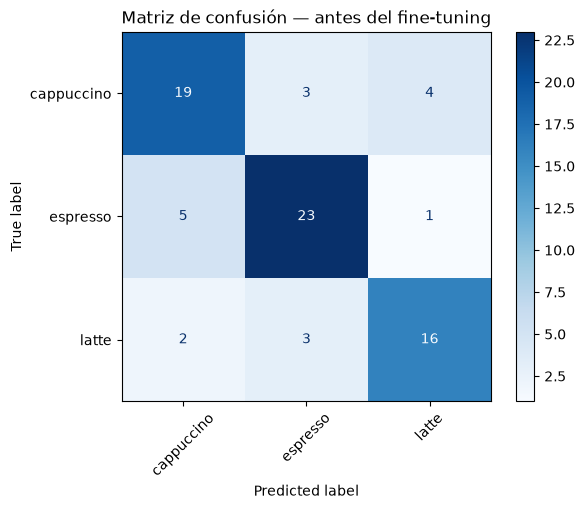

In [38]:
# Propósito: obtener las predicciones en test y analizarlas por clase (reporte y matriz de confusión).
# La accuracy global puede ocultar que una clase específica falla mucho.
def get_predictions(model, dataset):
    # Junta las etiquetas reales de todos los lotes en un solo arreglo.
    # Coinciden con las predicciones porque test_ds no se mezcla (shuffle=False).
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)  # forma (n_imágenes, 3): una probabilidad por clase
    y_pred = probabilities.argmax(axis=1)  # clase predicha = la de mayor probabilidad en cada fila
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
# Reporte por clase con 3 decimales. Fórmulas (VP = verdaderos positivos, FP = falsos positivos, FN = falsos negativos):
# precision = VP / (VP + FP); recall = VP / (VP + FN); F1 = 2 · precision · recall / (precision + recall).
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
# Matriz de confusión: filas = clase real, columnas = clase predicha.
# La diagonal son los aciertos; los números fuera de la diagonal muestran qué clases se confunden.
cm = confusion_matrix(y_true, y_pred)
# cmap="Blues": más oscuro = más imágenes; xticks_rotation=45 inclina los nombres para que no se encimen.
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

**Respuestas:**

1. **Mejor clase:** espresso, con F1 = 0.793 (precision y recall de 0.793). Le siguen latte (F1 = 0.762) y cappuccino (F1 = 0.731).
2. **Principal confusión:** espressos predichos como cappuccino, 5 de 29. La siguiente es cappuccino predicho como latte (4 de 26).
3. **¿La accuracy oculta un problema?** Poco: la accuracy es 0.763 y los recall por clase van de 0.731 a 0.793, así que ninguna clase falla mucho más que el promedio. Pero test tiene solo 76 imágenes: en cappuccino (26), un solo error mueve el recall unos 4 puntos, así que las diferencias entre clases no son concluyentes.
4. **Primer cambio en el dataset:** quitar las fotos sin bebida (tazas o vasos vacíos, juegos de tazas, collages) y las bebidas frías, que aparecen en la inspección y en los errores; después, revisar las imágenes con marca de agua.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [39]:
# Propósito: elegir qué capas de EfficientNet se descongelan para el fine-tuning (solo las últimas).
# Las capas finales detectan patrones más específicos; las primeras (bordes, texturas) sirven tal como vienen.
base_model.trainable = True  # primero se descongela toda la base...

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20  # punto de partida sugerido: pocas capas para no sobreajustar con un dataset pequeño

# ...y luego se vuelven a congelar todas menos las últimas N_UNFROZEN.
# [:-20] = desde la primera capa hasta la vigésima contando desde el final (sin incluirla).
for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
# BatchNormalization guarda promedios de ImageNet; con pocas imágenes, actualizarlos los volvería inestables.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Lectura: "X / Y" = capas marcadas como entrenables / total de capas de la base.
# X sale menor que 20 porque las BatchNormalization de ese tramo se volvieron a congelar.
print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),  # True cuenta como 1, False como 0
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

**Decisión de capas a descongelar:**
Se usa `N_UNFROZEN = 20`, el punto de partida sugerido. Así solo se adaptan las capas finales, que detectan patrones específicos (como la textura de la espuma), y se conservan las primeras, que detectan bordes y colores generales. Con ~100–150 imágenes por clase, descongelar muchas capas aumentaría el riesgo de sobreajuste.
**Resultado en validación:** quedaron 15 capas entrenables de 238 (las otras 5 del tramo son BatchNormalization, que se mantienen congeladas). Durante el fine-tuning, `val_loss` bajó en todas las épocas (0.4669 → 0.4369, frente a 0.4722 al final del modelo congelado) y `val_accuracy` subió de 0.8333 a 0.8611, sin señales de sobreajuste. Por eso se mantiene 20; como `val_loss` seguía bajando en la última época, más épocas podrían ayudar un poco.

In [ ]:
# TODO 5 — EN CASA: completa el fine-tuning
# Propósito: reentrenar la cabeza junto con las últimas capas descongeladas, con pasos muy pequeños.
# Hay que recompilar porque cambió qué capas son entrenables.

model.compile(
    # learning_rate=1e-5 (0.00001): 100 veces menor que antes, para ajustar los pesos de ImageNet
    # sin borrar lo que ya saben (pasos grandes los dañarían).
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),  # misma pérdida que en el TODO 3
    metrics=["accuracy"],
)

# Mismo criterio de parada que en el primer entrenamiento, para que la comparación sea justa.
early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,  # tope del rango sugerido (3–8); EarlyStopping corta antes si val_loss deja de mejorar
    callbacks=[early_stopping_ft],
)

Epoch 1/8


c:\Users\Emmanuel\Documents\ENTREGABLES IA\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


11/11 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.8432 - loss: 0.4425 - val_accuracy: 0.8333 - val_loss: 0.4669
Epoch 2/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 803ms/step - accuracy: 0.8669 - loss: 0.4321 - val_accuracy: 0.8333 - val_loss: 0.4630
Epoch 3/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 800ms/step - accuracy: 0.8521 - loss: 0.4181 - val_accuracy: 0.8194 - val_loss: 0.4570
Epoch 4/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 804ms/step - accuracy: 0.8669 - loss: 0.4139 - val_accuracy: 0.8333 - val_loss: 0.4524
Epoch 5/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 806ms/step - accuracy: 0.8580 - loss: 0.4244 - val_accuracy: 0.8333 - val_loss: 0.4485
Epoch 6/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 823ms/step - accuracy: 0.8462 - loss: 0.4164 - val_accuracy: 0.8611 - val_loss: 0.4423
Epoch 7/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 800ms/step - accuracy: 0.8669 - loss: 0.3838 - val_accuracy: 0.8611 - val_loss: 0.4393
Epoch 8/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 805ms/step - accuracy: 0.8580 - loss: 0.3947 - val_accuracy: 0.8611 - val_loss: 0.

# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [41]:
# Propósito: comparar la accuracy en te st antes y después del fine-tuning con el mismo conjunto.
# Usar el mismo test en ambos casos hace que la diferencia se deba solo al fine-tuning.
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
# Diferencia = después - antes; :+ muestra el signo: positivo = mejoró, negativo = empeoró.
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.7632
Después del fine-tuning: 0.7500
Diferencia              : -0.0132


              precision    recall  f1-score   support

  cappuccino      0.731     0.731     0.731        26
    espresso      0.767     0.793     0.780        29
       latte      0.750     0.714     0.732        21

    accuracy                          0.750        76
   macro avg      0.749     0.746     0.747        76
weighted avg      0.750     0.750     0.750        76



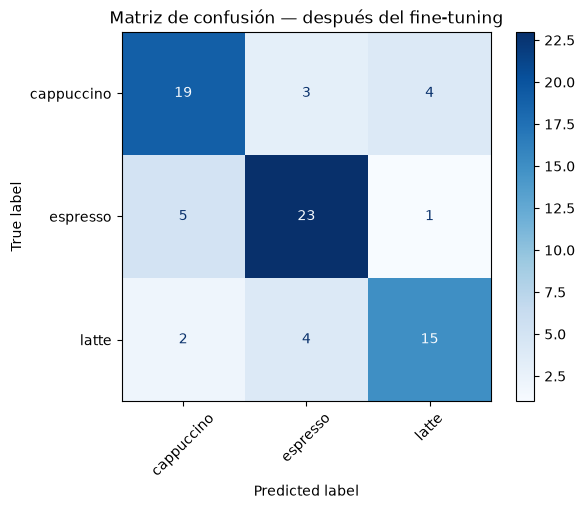

In [42]:
# Propósito: repetir el reporte por clase y la matriz de confusión con el modelo ajustado.
# Se compara con la matriz anterior para ver qué confusiones se corrigieron o aparecieron.
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)  # misma función de la sección 7
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))  # precision, recall y F1 por clase
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)  # filas = clase real, columnas = predicción
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

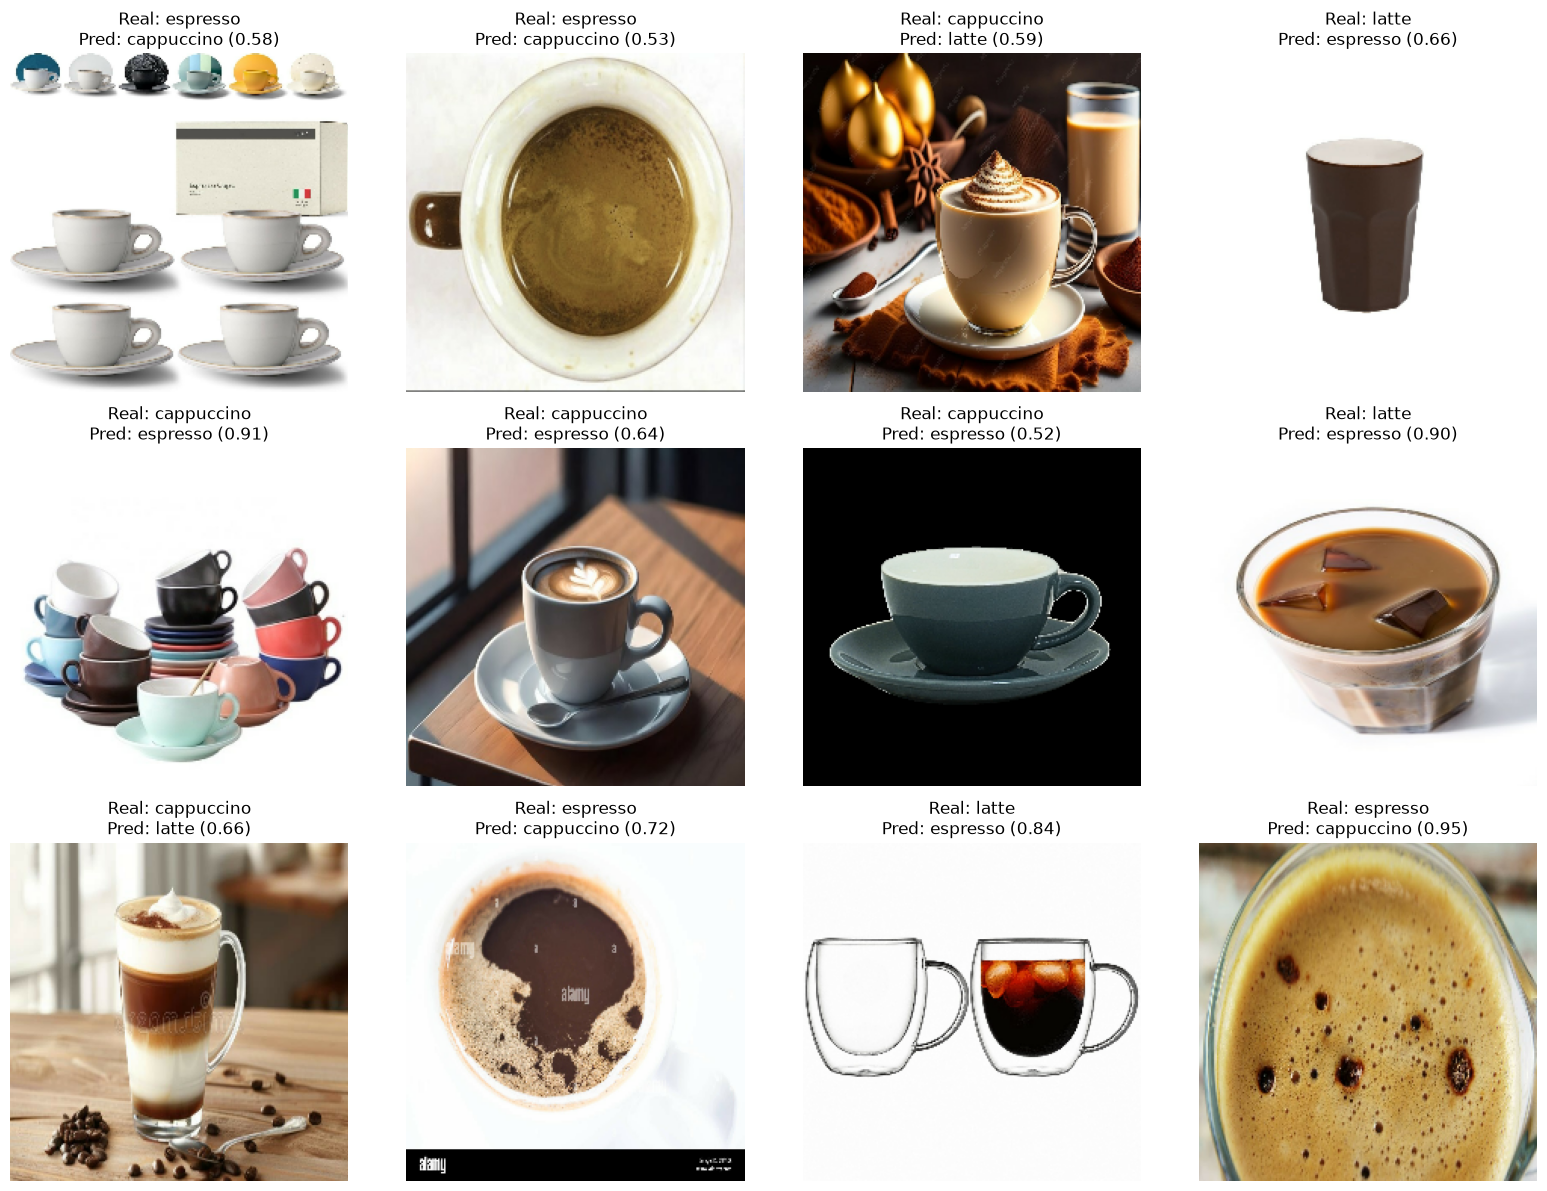

In [43]:
# Propósito: mostrar imágenes de test mal clasificadas para entender por qué falla el modelo.
# Las métricas dicen cuánto falla; ver los errores ayuda a explicar por qué.
def show_mistakes(dataset, model, class_names, max_images=12):  # max_images=12: tres filas de 4
    mistakes = []
    for images, labels in dataset:  # recorre test lote por lote
        probs = model.predict(images, verbose=0)  # probabilidades por clase de cada imagen del lote
        preds = probs.argmax(axis=1)  # clase predicha = la de mayor probabilidad
        # zip recorre a la vez cada imagen, su etiqueta real, su predicción y sus probabilidades.
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:  # solo guarda los errores
                # uint8 = enteros 0–255, el formato que imshow necesita para mostrar los colores bien.
                # prob[pred_label] = confianza del modelo en su predicción equivocada.
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)  # mezcla para no mostrar siempre los errores del primer lote
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))  # filas necesarias, redondeando hacia arriba
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)  # subplot numera desde 1
        ax.imshow(image)
        # Título: clase real, clase predicha y confianza. Una confianza alta en un error sugiere
        # una etiqueta mal puesta o un patrón engañoso (fondo, vaso).
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

Las imágenes son las de la celda `show_mistakes` (modelo después del fine-tuning); la columna 1 indica su posición en esa figura.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 (fila 1, col. 1) | espresso | cappuccino (0.58) | Foto de producto: juego de tazas vacías con su caja; no hay bebida | Eliminar fotos de producto y collages |
| 2 (fila 2, col. 1) | cappuccino | espresso (0.91) | Pila de tazas vacías de colores; la etiqueta solo viene de la búsqueda | Eliminar imágenes sin bebida |
| 3 (fila 2, col. 4) | latte | espresso (0.90) | Bebida fría con cubos en vaso bajo; no se parece a un latte caliente | Excluir bebidas frías o definirlas como otra clase |
| 4 (fila 3, col. 1) | cappuccino | latte (0.66) | Vaso alto con capas (estilo latte macchiato): visualmente es más parecido a un latte | Revisar la etiqueta; clase visualmente similar |
| 5 (fila 3, col. 4) | espresso | cappuccino (0.95) | Primer plano de la crema sin taza visible; la crema clara se parece a la espuma | Agregar más fotos de espresso con taza visible |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

**Conclusión:**

1. **Qué aprendí al construir el dataset:** el buscador devuelve como máximo ~35 imágenes por búsqueda, así que se necesitaron 5–6 búsquedas por clase; además trae muchas fotos que no muestran la bebida, y que TensorFlow pueda abrirlas no garantiza que sean buenos datos.
2. **Principal problema de calidad:** fotos de producto sin bebida (tazas o vasos vacíos, juegos de tazas), seguidas por bebidas frías y marcas de agua.
3. **Cambio en el desempeño:** la accuracy en test pasó de 0.7632 a 0.7500 (−0.0132), es decir, una imagen menos acertada de 76: un latte más se predijo como espresso; el resto de la matriz de confusión no cambió.
4. **¿Ayudó el fine-tuning?** En validación, un poco (`val_loss` 0.4722 → 0.4369; `val_accuracy` 0.8472 → 0.8611); en test, no. Una imagen de diferencia está dentro de la variación esperable con 76 imágenes. Con `learning_rate=1e-5` y solo 15 capas entrenables los cambios son pequeños, y varios errores vienen de imágenes mal escogidas, que el fine-tuning no puede corregir.
5. **Qué mejoraría primero:** los datos: limpiar las fotos sin bebida, las bebidas frías y los collages, y revisar las etiquetas dudosas. La mayoría de los errores analizados son de datos, no de arquitectura.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [44]:
# OPCIONAL
# Propósito: probar el modelo con una imagen externa (que no está en el dataset) para ver si generaliza.
# Para usarla, quita el "#" inicial de cada línea de código y pega una URL real de una foto de café.
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)  # descarga la imagen; espera máximo 10 s
# response.raise_for_status()  # lanza error si la descarga falló
# img = Image.open(io.BytesIO(response.content)).convert("RGB")  # abre los bytes como imagen RGB
# img_resized = img.resize(IMG_SIZE)  # 224x224, el mismo tamaño usado al entrenar
# x = np.array(img_resized, dtype="float32")[None, ...]  # [None, ...] agrega la dimensión de lote: (1, 224, 224, 3)
# p = model.predict(x, verbose=0)[0]  # [0] toma las 3 probabilidades de la única imagen
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")  # clase más probable y su probabilidad
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

**Respuesta:**

- **Base congelada (*feature extraction*, extracción de características):** solo se aprenden los pesos de la cabeza nueva (la capa Dense: 1280 × 3 + 3 = 3 843 parámetros). Todo el conocimiento para "ver" (bordes, texturas, formas) viene de ImageNet y no cambia.
- **Fine-tuning:** además de la cabeza, se ajustan las últimas capas de EfficientNet con un learning rate muy pequeño (1e-5). El conocimiento inicial sigue viniendo de ImageNet, pero se adapta a detalles del café, como la espuma o la crema.
- **Entrenar desde cero:** todos los pesos de la red (≈4 millones en EfficientNetB0) empiezan aleatorios y se aprenden solo con nuestras imágenes. No hay conocimiento previo, y con ~100–150 imágenes por clase el modelo probablemente sobreajustaría.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |